<a href="https://colab.research.google.com/github/reedx8/custom-cnn-dogvcat/blob/main/CNN_Dog_v_Cat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ConvNet training on a Dog vs Cat small dataset from Kaggle competition @ https://www.kaggle.com/competitions/dogs-vs-cats/data. Balanced binary classification problem. From DLWP book, 2026

# Login to kaggle IOT download Kaggle Dogs vs Cats dataset
import os
from google.colab import userdata
import zipfile

os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

# Downloading dogs vs cats dataset from kaggle:
!kaggle competitions download -c dogs-vs-cats

# Unzip dataset(dogs-vs-cats.zip) and then only unzip training images (train.zip -> /train folder)
with zipfile.ZipFile('dogs-vs-cats.zip', 'r') as zip_ref:
    zip_ref.extractall(".")

with zipfile.ZipFile('train.zip', 'r') as zip_ref:
    zip_ref.extractall(".")



100% 812M/812M [00:06<00:00, 141MB/s]



In [2]:
# Copying images to training, validation, and test directories
import os, shutil, pathlib
original_dir = pathlib.Path("train")
new_base_dir = pathlib.Path("dogs_vs_cats_small")

def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):
        dir = new_base_dir / subset_name / category
        os.makedirs(dir)
        fnames = [f"{category}.{i}.jpg" for i in range(start_index, end_index)]
        for fname in fnames:
            shutil.copyfile(src=original_dir / fname, dst=dir / fname)

make_subset("train", start_index=0, end_index=1000)
make_subset("validation", start_index=1000, end_index=1500)
make_subset("test", start_index=1500, end_index=2500)

# directory should now look like the following:
# dogs_vs_cats_small/
# ...train/
# ......cat/   <- contains 1000 cat images
# ......dog/   <- contains 1000 dog images
# ...validation/
# ......cat/   <- contains 500 cat images
# ......dog/   <- contains 500 dog images
# ...test/
# ......cat/   <- 1000 cat iamges
# ......dog/   <- 1000 dog images



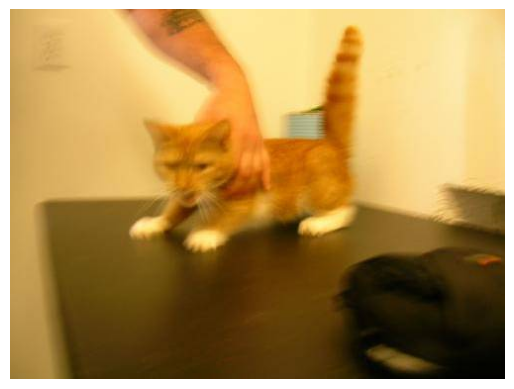

In [3]:
from keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt

# 1. Load the image
img = load_img('/content/dogs_vs_cats_small/train/cat/cat.0.jpg')

# 2. Convert the image to a NumPy array IOT view it in colab
img_array = img_to_array(img)

# 3. Plot the raw pixel data using matplotlib
plt.imshow(img_array.astype('uint8'))
plt.axis('off') # Hide the pixel grid axes
plt.show()

In [4]:
# Instantiating a small ConvNet for dogs vs cats classification, and compiling
import keras
from keras import layers

inputs = keras.Input(shape=(180, 180, 3)) # Model will expect RBG images of size 180 x 180 (see below)
x = layers.Rescaling(1.0/255)(inputs) # Rescales inputs to the [0,1] range by dividing them by 255
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x) # flattens the 3d activations with shape (height, width, 512) into 1D activations with shape (512,) by avg'ing them over spatial dimensions
outputs = layers.Dense(units=1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

# model.summary()

model.compile(
	loss='binary_crossentropy',
	optimizer='adam',
	metrics=['accuracy'],
)


In [5]:
# Preprocess data -- only 2,000 *training* samples total
from keras.utils import image_dataset_from_directory as img_data

# new_base_dir = dogs_vs_cats_small/

batch_size = 64
image_size = (180,180) # image size you want
train_dataset = img_data(new_base_dir / "train", image_size=image_size, batch_size=batch_size)
validation_dataset = img_data(new_base_dir / "validation", image_size=image_size, batch_size=batch_size)
test_dataset = img_data(new_base_dir / "test", image_size=image_size, batch_size=batch_size)



Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


In [6]:
# fit the model
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]
history = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 206s 6s/step - accuracy: 0.5185 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 197s 6s/step - accuracy: 0.5635 - loss: 0.6830 - val_accuracy: 0.5370 - val_loss: 0.6811
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 184s 6s/step - accuracy: 0.6005 - loss: 0.6577 - val_accuracy: 0.5960 - val_loss: 0.6415
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 179s 6s/step - accuracy: 0.6325 - loss: 0.6402 - val_accuracy: 0.6510 - val_loss: 0.6279
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 197s 6s/step - accuracy: 0.6370 - loss: 0.6246 - val_accuracy: 0.5930 - val_loss: 0.7000
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 196s 6s/step - accuracy: 0.6680 - loss: 0.6107 - val_accuracy: 0.7010 - val_loss: 0.5822
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 203s 6s/step - accuracy: 0.7040 - loss: 0.5681 - val_accuracy: 0.7200 - val_loss: 0.5595
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 203s 6s/step - accuracy: 0.7170 - loss: 0.5601 - val_accuracy: 0.6720 - v

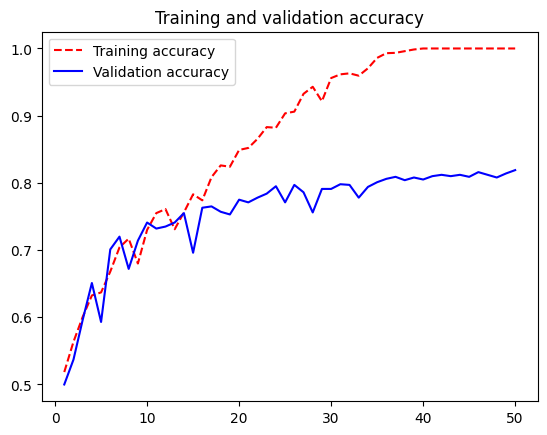

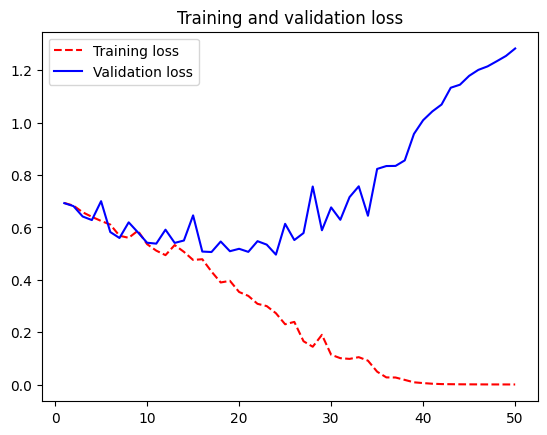

In [7]:
# Plotting the loss and accuracy of the model over the training and validation data
import matplotlib.pyplot as plt

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)

plt.plot(epochs, accuracy, "r--", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.figure()

plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

In [8]:
# Run model against final test data -- 78.8% test accuracy
test_model = keras.models.load_model("convnet_from_scratch.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f'Test accuracy: ${test_acc:.3f}')

32/32 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.7880 - loss: 0.4786
Test accuracy: $0.788


In [12]:
# TODO -- Defining a data augmentation stage to mitigate overfitting identified in valid vs training chart
import tensorflow as tf
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
]

def data_augmentation(images, targets):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images, targets

augmented_train_dataset = train_dataset.map(
    data_augmentation, num_parallel_calls=8
)
augmented_train_dataset = augmented_train_dataset.prefetch(tf.data.AUTOTUNE)